# Where does the SWPC 3-day Kp forecast sheet come from?

`raw_data/SWPC_Kp_Forecasts_2011_2025.csv` (the "SWPC sheet") is an internal SWPC table of 7-day, 3-hourly Kp forecasts. Each row is labelled only with a `Forecast Day` date, so we don't know when its values were issued or which public product they correspond to. This notebook compares the sheet's first three days with the three public SWPC products that carry a 3-day, 3-hourly Kp table:

| product | issued (UT) | Kp table covers | local files |
|---|---|---|---|
| `geomag_forecast` | ~22:05 on day *D* | *D*+1 … *D*+3 | 2022-11-13 → 2026-11-17 |
| `three_day_forecast` 0030 | 00:30 on day *D* | *D* … *D*+2 | 2022-03-25 → 2026-11-17 |
| `three_day_forecast` 1230 | 12:30 on day *D* | *D* … *D*+2 | 2022-03-25 → 2026-11-17 |

The sheet ends on 2025-09-29, so the comparison covers 2022-03-25 → 2025-09-29 for the three_day reports and 2022-11-13 → 2025-09-29 for geomag_forecast. This addresses two TODO items: *compare the SWPC sheet with geomag_forecast and three_day_forecast to find its source*, and *resolve the issue time of the SWPC sheet forecasts*.

### Summary of findings

1. **The sheet row for Forecast Day *D* forecasts *D*+1 … *D*+3.** The `Forecast Start = Forecast Day + 1` convention in `extracted_data/SWPC_3day_3hr_Kp.csv` is correct. No other alignment gives more than ~22 % agreement.
2. **The closest public product is the `geomag_forecast` issued at ~22 UT on *D*.** 90.4 % of sheet rows are identical to it in all 24 slots, and 97.9 % of individual slots match.
3. **The 0030 `three_day_forecast` of *D*+1 is the same forecast two and a half hours later.** It matches 83 % of rows. It agrees with geomag on days 2–3 about 98 % of the time, but revises day 1 on about 24 % of days. When it does, the sheet usually keeps the 22 UT values (122 days vs 52). When geomag and 0030 differ on days 2–3, the sheet nearly always follows 0030 (24 of 28 days).
4. **The 1230 `three_day_forecast` is not the source.** It is a genuine mid-day update: no 1230 report from *D* or *D*+1 reproduces a sheet row (≤ 2.8 % rows identical), and only 34 % of its day-1 slots match.
5. **The sheet stores the forecaster's values in thirds even when the public products didn't.** Until the 2022-11-14 1230 report, `three_day_forecast` published whole-number Kp. Rounding the sheet to whole numbers reproduces those reports with the same pattern as later (80.6 % of rows identical to 0030 *D*+1, days 2–3 at 100 %).
6. **Implication for the issue time:** the sheet's values were public by ~22:00–22:15 UT on Forecast Day *D*, and some day-1 revisions made up to 00:30 on *D*+1 reach it. The extracted CSVs therefore declare the sheet issued at *D* 21:00 UTC, just before the geomag_forecast it is anchored to (`Start Offset` 3 h; see *Conclusions*).

In [1]:
import sys
dir_path = '/Users/henry/Desktop/SWxResearch/Code/KpAp-forecast-verification'
if dir_path not in sys.path:
    sys.path.insert(0, dir_path)

import os
os.chdir(dir_path)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.extract_forecasts_utils import THREE_DAY_FORECAST_EXCLUDED_FILES

pd.set_option('display.width', 200)

LEADS = [f'{3*(i+1)}hrKp' for i in range(24)]
SLOT_LABELS = [f'{3*i:02d}-{(3*i+3) % 24:02d}' for i in range(8)]
ATOL = 0.005  # Kp values are given to 2 dp (thirds), so "equal" means within rounding

# Fixed colour per product, used in every plot
COLORS = {'geomag 22UT': '#2a78d6', '3day 0030': '#eb6834', '3day 1230': '#1baf7a'}
NEUTRAL = '#8a8984'
DAY_COLORS = ['#9ec5f4', '#4f94e0', '#1a5aa8']  # sheet lead day 1-3 (sequential: ordinal)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'figure.dpi': 110})

## 1. Load the data

All three products come from the extracted CSVs in `extracted_data/`. The rows that `fill_nans_func` inserts for missing reports are dropped, since only real reports are compared here. The SWPC sheet's `Forecast Start` column is an assumption made during extraction, so this notebook keys the sheet on `Forecast Day` only, and Section 2 tests that assumption.

In [2]:
def load_forecast_csv(file_path):
    """Load an extracted forecast csv, dropping the NaN rows inserted for missing reports."""
    df = pd.read_csv(file_path, parse_dates=['Forecast Issued', 'Forecast Start'])
    return df.dropna(subset=['Forecast Issued']).reset_index(drop=True)


# SWPC sheet: the raw sheet has no issue time. The extracted csv declares it issued at 21:00 UTC on
# the sheet's 'Forecast Day' (the conclusion of this notebook), so Forecast Day is the issue date.
# 'Forecast Start' = Forecast Day + 1 is the alignment Section 2 tests, so the comparisons below
# key the sheet on Forecast Day only.
df_sheet = load_forecast_csv('extracted_data/SWPC_3day_3hr_Kp.csv')
df_sheet['Forecast Day'] = df_sheet['Forecast Issued'].dt.normalize()

df_geomag = load_forecast_csv('extracted_data/geomag_forecast_3day_3hr_Kp.csv')
df_geomag['Issue Day'] = df_geomag['Forecast Issued'].dt.normalize()

print(f'SWPC sheet:      {len(df_sheet)} rows, {df_sheet["Forecast Day"].min().date()} to {df_sheet["Forecast Day"].max().date()}, '
      f'{df_sheet[LEADS].isna().any(axis=1).sum()} rows with a missing value')
print(f'geomag_forecast: {len(df_geomag)} rows, {df_geomag["Issue Day"].min().date()} to {df_geomag["Issue Day"].max().date()}, '
      f'issue times: {df_geomag["Forecast Issued"].dt.strftime("%H%M").value_counts().to_dict()}')

SWPC sheet:      5053 rows, 2011-11-28 to 2025-09-29, 0 rows with a missing value
geomag_forecast: 1183 rows, 2022-11-13 to 2026-11-17, issue times: {'2205': 873, '2200': 267, '2210': 36, '2215': 6, '2230': 1}


`three_day_forecast` comes from `extracted_data/three_day_forecast_3day_3hr_Kp.csv`, written by `get_three_day_forecast` in `src/extract_forecasts_utils.py`. That CSV has one row per 12 hr slot from the first report to the last: 00 UT holds the 0030 report and 12 UT the 1230 report. Each report sits in the slot from its **filename**, not its header, because a few 1230 reports were issued late (below). The CSV doesn't store the slot, so it is rebuilt from row position, and each report is labelled 0030 or 1230 from it. `Forecast Start` is the first day of each Kp table, which is the slot's day.

In [3]:
def load_three_day_forecast_csv(file_path='extracted_data/three_day_forecast_3day_3hr_Kp.csv'):
    """
    Load the extracted three_day_forecast csv and label each row with its 12 hr 'Slot' and 'Product'.

    The csv has one row per 12 hr slot (00 UT = 0030 report, 12 UT = 1230 report) from the first report
    to the last, including NaN rows for missing reports, so each row's slot is rebuilt from its position.
    The NaN rows are kept here so missing slots can be counted.
    """
    df = pd.read_csv(file_path, parse_dates=['Forecast Issued', 'Forecast Start'])
    slots = pd.date_range(df['Forecast Issued'].iloc[0].floor('12h'), periods=len(df), freq='12h')
    # Each Kp table (and each inferred start of a missing report) begins on its slot's day
    assert (df['Forecast Start'] == slots.normalize()).all()
    df['Slot'] = slots
    df['Product'] = np.where(slots.hour == 0, '3day 0030', '3day 1230')
    return df


df_3day_all = load_three_day_forecast_csv()
df_3day = df_3day_all.dropna(subset=['Forecast Issued']).reset_index(drop=True)

print('Header issue hours:', df_3day['Forecast Issued'].dt.hour.value_counts().sort_index().to_dict())
for name, g in df_3day_all.groupby('Product'):
    n = g['Forecast Issued'].notna().sum()
    print(f'{name}: {n} reports, {len(g) - n} missing slots, {g["Forecast Start"].min().date()} to {g["Forecast Start"].max().date()}')

Header issue hours: {0: 1318, 1: 1, 2: 2, 3: 2, 4: 1, 5: 1, 12: 1319, 13: 1, 15: 1, 18: 1}
3day 0030: 1323 reports, 376 missing slots, 2022-03-25 to 2026-11-17
3day 1230: 1324 reports, 375 missing slots, 2022-03-25 to 2026-11-17


In [4]:
# Data-quality checks
# 1. Files the pipeline skips (THREE_DAY_FORECAST_EXCLUDED_FILES); their slots are missing reports
print('Files excluded during extraction:')
display(pd.Series(THREE_DAY_FORECAST_EXCLUDED_FILES, name='reason').rename_axis('file').to_frame())

# 2. Reports whose header issue time is not on the day of their slot (late issues)
late = df_3day['Forecast Start'] != df_3day['Forecast Issued'].dt.normalize()
print('Reports issued after their nominal day (kept in their filename slot):')
display(df_3day.loc[late, ['Slot', 'Forecast Issued', 'Forecast Start']])

# 3. Other reports issued in a later hour than scheduled (00 UT or 12 UT), on their own day
off_schedule = ~late & (df_3day['Forecast Issued'].dt.floor('h') != df_3day['Slot'])
print(f'{off_schedule.sum()} further reports issued off schedule on their own day:')
display(df_3day.loc[off_schedule, ['Slot', 'Forecast Issued', 'Start Offset (hr)']])

# Every product has exactly one report per table start date
assert not df_3day.duplicated(['Product', 'Forecast Start']).any()

Files excluded during extraction:


,reason
file,
202510071230three_day_forecast.txt,invalid Kp value
202405140030three_day_forecast.txt,mistyped issue time (header 2024 May 14 1225)
202502110030three_day_forecast.txt,mistyped issue time (header 2025 Feb 11 1235)
202504260030three_day_forecast.txt,mistyped issue time (header 2025 Apr 26 1225)


Reports issued after their nominal day (kept in their filename slot):


,Slot,Forecast Issued,Forecast Start
1012,2024-07-08 12:00:00,2024-07-09 00:20:00,2024-07-08
1674,2025-07-16 12:00:00,2025-07-17 00:05:00,2025-07-16


10 further reports issued off schedule on their own day:


,Slot,Forecast Issued,Start Offset (hr)
843,2024-03-13 00:00:00,2024-03-13 02:05:00,-2.08
1358,2025-02-07 00:00:00,2025-02-07 04:55:00,-4.92
1383,2025-02-20 12:00:00,2025-02-20 13:05:00,-13.08
1582,2025-05-31 12:00:00,2025-05-31 15:35:00,-15.58
1907,2025-11-11 12:00:00,2025-11-11 18:40:00,-18.67
1956,2025-12-06 00:00:00,2025-12-06 03:15:00,-3.25
2071,2026-02-02 00:00:00,2026-02-02 01:40:00,-1.67
2413,2026-07-24 00:00:00,2026-07-24 02:30:00,-2.50
2497,2026-09-04 00:00:00,2026-09-04 03:05:00,-3.08
2557,2026-10-04 00:00:00,2026-10-04 05:20:00,-5.33


### Data-quality notes

The extraction already handles the bad files, so the CSV needs no further cleaning here:

- **Four files are excluded** (`THREE_DAY_FORECAST_EXCLUDED_FILES`). `202510071230` contains an invalid Kp value (3.37), and three 0030 reports (`202405140030`, `202502110030`, `202504260030`) have headers that mistype the issue time as ~12:25. Their slots are missing reports. Only the three 0030 files fall inside the sheet's date range.
- **Three files are stale copies** of the previous report, with an identical header issue time and Kp table: `202205221230`, `202205230030` and `202206271230`. `drop_repeated_reports` drops them, so those three slots are missing too.
- **Two 1230 reports were issued late**, just after midnight: `202407081230` was issued 2024-07-09 00:20, and `202507161230` was issued 2025-07-17 00:05. Their tables start on the filename date, and they are kept in their 1230 slot.
- There are 10 further reports issued an hour or more late on their own day (e.g. 02:05 or 13:05). These look like re-issues, and their tables still start on the issue day.

### Precision of the public products

The table below shows that **every public Kp table up to the one starting 2022-11-14 is whole numbers** (the 0030 and 1230 three_day reports, plus the very first geomag file). Every table from 2022-11-15 on is in thirds. The switch happened between the 2022-11-14 1230 report and that evening's geomag_forecast. The sheet is in thirds throughout. So every comparison below goes through `kp_equal`, which rounds the sheet to whole numbers when the product table comes from the whole-number era. Section 5 shows why this matters.

In [5]:
def is_whole_number_table(df):
    """True for reports whose 24 Kp values are all whole numbers."""
    v = df[LEADS].to_numpy()
    return np.isclose(v, np.round(v), atol=ATOL).all(axis=1)


precision = []
for name, df in [('geomag 22UT', df_geomag),
                 ('3day 0030', df_3day[df_3day['Product'] == '3day 0030']),
                 ('3day 1230', df_3day[df_3day['Product'] == '3day 1230'])]:
    whole = is_whole_number_table(df)
    precision.append({'product': name, 'reports': len(df), 'whole-number tables': whole.sum(),
                      'last whole-number table start': df.loc[whole, 'Forecast Start'].max(),
                      'first thirds table start': df.loc[~whole, 'Forecast Start'].min()})
precision = pd.DataFrame(precision).set_index('product')
display(precision)

# Public products switched from whole numbers to thirds between the 2022-11-14 1230 and 2205 reports.
# Comparisons against tables starting on or before this date round the sheet to whole numbers first.
INTEGER_ERA_LAST_START = pd.Timestamp('2022-11-14')
assert (precision['last whole-number table start'].dropna() <= INTEGER_ERA_LAST_START).all()
assert (precision['first thirds table start'] > INTEGER_ERA_LAST_START).all()


def kp_equal(sheet_vals, prod_vals, table_starts):
    """
    Slot-wise equality of sheet and product Kp at the product's precision.

    sheet_vals and prod_vals are (n, 24) arrays with one table start per row, or 1-D arrays with one table
    start per value. Sheet values are rounded to whole numbers where the table starts in the whole-number era.
    """
    s = np.array(sheet_vals, dtype=float)
    whole = pd.DatetimeIndex(np.asarray(table_starts)) <= INTEGER_ERA_LAST_START
    s[whole] = np.round(s[whole])
    return np.isclose(s, prod_vals, atol=ATOL)

,reports,whole-number tables,last whole-number table start,first thirds table start
product,,,,
geomag 22UT,1183,1,2022-11-14,2022-11-15
3day 0030,1323,144,2022-11-14,2022-11-15
3day 1230,1324,142,2022-11-14,2022-11-15


Each product is indexed by **table start**, i.e. 00 UT on the first day of its Kp table. For geomag this is the day after issue; for three_day it is the issue day.

In [6]:
# Every product indexed by its table start date (00 UT on the first forecast day)
products = {
    'geomag 22UT': df_geomag.set_index('Forecast Start')[LEADS],
    '3day 0030': df_3day[df_3day['Product'] == '3day 0030'].set_index('Forecast Start')[LEADS],
    '3day 1230': df_3day[df_3day['Product'] == '3day 1230'].set_index('Forecast Start')[LEADS],
}
# Table start relative to the nominal issue day: geomag tables start the day after issue, three_day tables on the issue day
TABLE_START_AFTER_ISSUE_DAY = {'geomag 22UT': 1, '3day 0030': 0, '3day 1230': 0}
NOMINAL_ISSUE_HOUR = {'geomag 22UT': 22.0, '3day 0030': 0.5, '3day 1230': 12.5}

sheet = df_sheet.set_index('Forecast Day')[LEADS]

## 2. Which days does a sheet row forecast?

Section 2 compares sheet row *D* with each product's report whose table starts on *D* + lag. The comparison is position by position, so sheet day *k* slot *s* is matched to table day *k* slot *s*. It records the fraction of slots that match and the fraction of rows where all 24 slots match.

In [7]:
def match_on_table_start(sheet, prod, lag_days):
    """
    Compares sheet row 'Forecast Day' = D with the product report whose table starts on D + lag_days,
    position by position (sheet day k slot s vs product table day k slot s), at the product's precision.

    Returns the number of shared rows, the fraction of the 24 slots that match, and the fraction of
    rows where all 24 slots match.
    """
    sh = sheet.copy()
    sh.index = sh.index + pd.Timedelta(days=lag_days)
    idx = sh.index.intersection(prod.index)
    eq = kp_equal(sh.loc[idx].to_numpy(), prod.loc[idx].to_numpy(), idx)
    return {'rows': len(idx), 'slot match': eq.mean(), 'row identical': eq.all(axis=1).mean()}


lag_scan = pd.DataFrame([{'product': name, 'lag (days)': lag, **match_on_table_start(sheet, prod, lag)}
                         for name, prod in products.items() for lag in range(-2, 3)])
display(lag_scan.pivot(index='lag (days)', columns='product', values=['slot match', 'row identical']).round(3))

slot match                       row identical                      
product     3day 0030 3day 1230 geomag 22UT     3day 0030 3day 1230 geomag 22UT
lag (days)                                                                     
-2              0.148     0.139       0.119         0.000     0.000       0.000
-1              0.154     0.146       0.122         0.000     0.000       0.000
 0              0.213     0.205       0.178         0.000     0.000       0.000
 1              0.962     0.746       0.979         0.826     0.008       0.904
 2              0.215     0.198       0.177         0.001     0.001       0.000

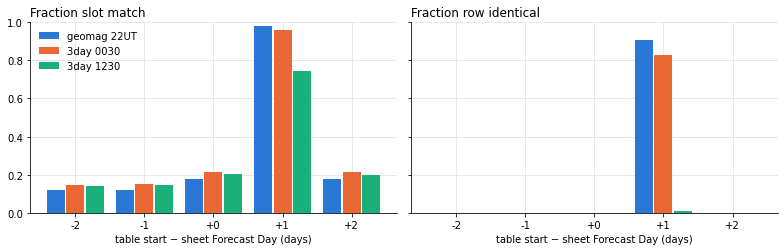

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
width = 0.26
lags = np.arange(-2, 3)
for ax, metric in zip(axes, ['slot match', 'row identical']):
    for j, name in enumerate(products):
        y = lag_scan[lag_scan['product'] == name][metric].to_numpy()
        ax.bar(lags + (j - 1) * (width + 0.02), y, width, color=COLORS[name], label=name)
    ax.set_xticks(lags, [f'{l:+d}' for l in lags])
    ax.set_xlabel('table start − sheet Forecast Day (days)')
    ax.set_title(f'Fraction {metric}', loc='left')
    ax.set_ylim(0, 1)
axes[0].legend(frameon=False, loc='upper left')
fig.tight_layout()
plt.show()

**Result.** Only lag = +1 shows agreement beyond chance. At any other lag, 12–22 % of slots match (the background rate for quiet-time Kp values that repeat) and no rows are identical. At lag +1:

| product (table start *D*+1) | slot match | row identical |
|---|---|---|
| geomag 22 UT, issued *D* | 0.979 | 0.904 |
| three_day 0030, issued *D*+1 | 0.962 | 0.826 |
| three_day 1230, issued *D*+1 | 0.746 | 0.008 |

So **sheet day 1 is *D*+1**, and the extracted `Forecast Start = Forecast Day + 1` is right. The question becomes which issuance covering *D*+1 … *D*+3 the sheet copies. The geomag report from the evening of *D* and the 0030 report from just after midnight are both close candidates. The 1230 report from *D*+1 shares most of days 2–3 but almost never a full row.

## 3. Every issuance around Forecast Day *D*, on valid time

Section 2 aligned tables by position. Here every candidate issuance in the two days around *D* is compared with the sheet on **valid time**, i.e. on whichever 3 hr slots both forecast. For example, the 1230 report issued on *D* covers *D* … *D*+2, so it shares sheet days 1–2. The comparison uses the 751 Forecast Days on which all seven candidate reports exist, so every candidate is scored on the same days. Candidates are listed in order of issue time, relative to 00 UT on *D*.

In [9]:
def to_valid_time(df, issue_day, table_start):
    """Long format, one row per (issue day, valid 3 hr slot)."""
    valid = table_start.to_numpy()[:, None] + np.arange(24) * np.timedelta64(3, 'h')
    return pd.DataFrame({'issue_day': np.repeat(issue_day.to_numpy(), 24),
                         'table_start': np.repeat(table_start.to_numpy(), 24),
                         'valid': valid.ravel(),
                         'Kp': df[LEADS].to_numpy().ravel()})


# Sheet: Forecast Start = Forecast Day + 1 (confirmed in Section 2); lead day 1-3 within the sheet's 3 day table
sheet_long = to_valid_time(sheet, sheet.index.to_series(), sheet.index.to_series() + pd.Timedelta(days=1))
sheet_long['sheet day'] = np.tile(np.repeat([1, 2, 3], 8), len(sheet))

prod_long = {}
for name, prod in products.items():
    starts = prod.index.to_series()
    issue_days = starts - pd.Timedelta(days=TABLE_START_AFTER_ISSUE_DAY[name])
    prod_long[name] = to_valid_time(prod, issue_days, starts)

# Candidate issuances around Forecast Day D, in chronological order
candidates = [('geomag 22UT', -1), ('3day 0030', 0), ('3day 1230', 0), ('geomag 22UT', 0),
              ('3day 0030', 1), ('3day 1230', 1), ('geomag 22UT', 1)]


def cand_label(name, off):
    day = 'D' if off == 0 else f'D{off:+d}'
    return f'{name.split()[0]} {name.split()[1]} {day}'


# Restrict to Forecast Days where every candidate issuance exists so all candidates are scored on the same days
common_days = sheet.index
for name, off in candidates:
    issue_days = prod_long[name]['issue_day'].drop_duplicates()
    common_days = common_days.intersection(pd.DatetimeIndex(issue_days - pd.Timedelta(days=off)))
print(f'{len(common_days)} Forecast Days with all 7 candidate issuances '
      f'({common_days.min().date()} to {common_days.max().date()})')

rows = []
for name, off in candidates:
    p = prod_long[name].copy()
    p['issue_day'] = p['issue_day'] - pd.Timedelta(days=off)  # re-key to the sheet's Forecast Day
    m = sheet_long[sheet_long['issue_day'].isin(common_days)].merge(p, on=['issue_day', 'valid'], suffixes=('_sheet', '_prod'))
    m['match'] = kp_equal(m['Kp_sheet'], m['Kp_prod'], m['table_start_prod'])
    row = {'candidate': cand_label(name, off), 'product': name,
           'issue time rel. D 00UT (hr)': NOMINAL_ISSUE_HOUR[name] + 24 * off,
           'overall': m['match'].mean()}
    for k in (1, 2, 3):
        mk = m[m['sheet day'] == k]
        row[f'sheet day {k}'] = mk['match'].mean() if len(mk) else np.nan
    rows.append(row)

valid_time_match = pd.DataFrame(rows).set_index('candidate')
display(valid_time_match.round(3))

751 Forecast Days with all 7 candidate issuances (2022-11-14 to 2025-09-29)


,product,issue time rel. D 00UT (hr),overall,sheet day 1,sheet day 2,sheet day 3
candidate,,,,,,
geomag 22UT D-1,geomag 22UT,-2.0,0.695,0.663,0.727,NaN
3day 0030 D,3day 0030,0.5,0.701,0.666,0.736,NaN
3day 1230 D,3day 1230,12.5,0.743,0.703,0.782,NaN
geomag 22UT D,geomag 22UT,22.0,0.979,0.962,0.990,0.985
3day 0030 D+1,3day 0030,24.5,0.959,0.881,0.998,1.000
3day 1230 D+1,3day 1230,36.5,0.737,0.335,0.944,0.931
geomag 22UT D+1,geomag 22UT,46.0,0.714,NaN,0.688,0.740


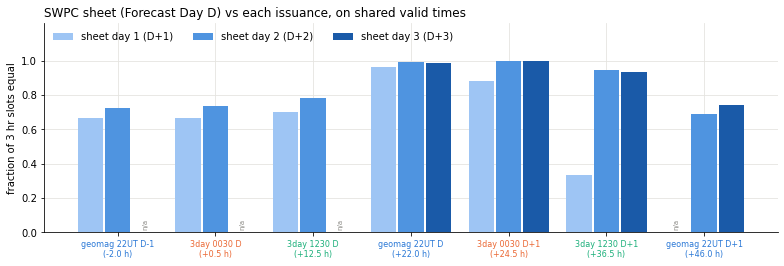

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(valid_time_match))
width = 0.26
for k in (1, 2, 3):
    y = valid_time_match[f'sheet day {k}'].to_numpy()
    ax.bar(x + (k - 2) * (width + 0.02), np.nan_to_num(y), width, color=DAY_COLORS[k - 1],
           label=f'sheet day {k} (D+{k})')
    for xi, yi in zip(x, y):
        if np.isnan(yi):
            ax.text(xi + (k - 2) * (width + 0.02), 0.02, 'n/a', ha='center', fontsize=7, color=NEUTRAL, rotation=90)
labels = [f'{c}\n({h:+.1f} h)' for c, h in zip(valid_time_match.index, valid_time_match['issue time rel. D 00UT (hr)'])]
ax.set_xticks(x, labels, fontsize=8)
for tick, name in zip(ax.get_xticklabels(), valid_time_match['product']):
    tick.set_color(COLORS[name])
ax.set_ylim(0, 1.22)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel('fraction of 3 hr slots equal')
ax.set_title('SWPC sheet (Forecast Day D) vs each issuance, on shared valid times', loc='left')
ax.legend(frameon=False, ncols=3, loc='upper left')
fig.tight_layout()
plt.show()

**Result.** Agreement peaks sharply at the two reports issued around midnight between *D* and *D*+1:

- **geomag 22 UT, *D* (−2 h before *D*+1 begins): 97.9 % of slots.** This is the best match overall. Day 1 is 96.2 %, day 2 99.0 %, day 3 98.5 %.
- **0030, *D*+1: 95.9 %**, with a different profile. Days 2–3 are essentially perfect (99.8 % and 100 %), but day 1 is only 88.1 %.
- Reports issued earlier (geomag *D*−1, 0030 *D*, 1230 *D*) agree on 69–74 % of shared slots. That is the level expected from a forecast issued 12–24 h earlier for the same hours.
- The 1230 report on *D*+1 is the one where the forecaster has revised the current day by mid-day, so day 1 drops to 33.5 %. Its days 2–3 are still 93–94 % identical. The geomag report on *D*+1 agrees on only ~71 %.

The forecast evolves steadily, and the sheet's snapshot sits between ~22:00 on *D* and 00:30 on *D*+1. geomag and 0030 fall within that window and differ mostly on day 1, so the next section looks at the days where they disagree.

## 4. When geomag (22 UT, *D*) and 0030 (*D*+1) disagree, which does the sheet carry?

Both reports forecast exactly *D*+1 … *D*+3, so they can be compared directly. For each Forecast Day and sheet lead day, each lead day is labelled by which product's 8 slots the sheet equals: both, geomag only, 0030 only, or neither.

In [11]:
def lead_day_status(sheet, geomag, a0030, tol=ATOL):
    """
    For each Forecast Day D and sheet lead day k: whether the sheet's 8 slots equal geomag(D) and/or 0030(D+1).
    All three cover the same valid days (D+1 .. D+3) at the same table positions.
    """
    days = sheet.index.intersection(geomag.index - pd.Timedelta(days=1)).intersection(a0030.index - pd.Timedelta(days=1))
    starts = days + pd.Timedelta(days=1)
    S = sheet.loc[days].to_numpy()
    G = geomag.loc[starts].to_numpy()
    A = a0030.loc[starts].to_numpy()
    eq_sg = kp_equal(S, G, starts).reshape(-1, 3, 8)
    eq_sa = kp_equal(S, A, starts).reshape(-1, 3, 8)
    eq_ga = np.isclose(G, A, atol=tol).reshape(-1, 3, 8)  # same table start, so same precision
    return days, eq_sg, eq_sa, eq_ga


days4, eq_sg, eq_sa, eq_ga = lead_day_status(sheet, products['geomag 22UT'], products['3day 0030'])
print(f'{len(days4)} Forecast Days with sheet, geomag(D) and 0030(D+1)')

# Per lead day: does the whole day (8 slots) match?
sg_day, sa_day, ga_day = eq_sg.all(-1), eq_sa.all(-1), eq_ga.all(-1)
cat = np.select([sg_day & sa_day, sg_day & ~sa_day, ~sg_day & sa_day],
                ['both (geomag = 0030)', 'geomag only', '0030 only'], 'neither')
day_cats = pd.DataFrame(cat, index=days4, columns=['day 1', 'day 2', 'day 3'])

print('\nWhole lead day: which product does the sheet equal?')
display(day_cats.apply(pd.Series.value_counts).fillna(0).astype(int))
print('Fraction of days where geomag(D) and 0030(D+1) are identical:', dict(zip(['day 1', 'day 2', 'day 3'], ga_day.mean(0).round(3))))

767 Forecast Days with sheet, geomag(D) and 0030(D+1)

Whole lead day: which product does the sheet equal?


,day 1,day 2,day 3
0030 only,52,8,16
both (geomag = 0030),584,755,751
geomag only,122,3,0
neither,9,1,0


Fraction of days where geomag(D) and 0030(D+1) are identical: {'day 1': np.float64(0.763), 'day 2': np.float64(0.986), 'day 3': np.float64(0.979)}


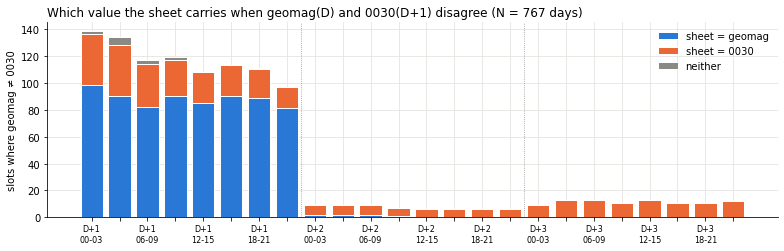

Row patterns (day 1 | day 2 | day 3):


,Forecast Days
both (geomag = 0030) | both (geomag = 0030) | both (geomag = 0030),571
geomag only | both (geomag = 0030) | both (geomag = 0030),119
0030 only | both (geomag = 0030) | both (geomag = 0030),45
both (geomag = 0030) | both (geomag = 0030) | 0030 only,11
neither | both (geomag = 0030) | both (geomag = 0030),7
0030 only | 0030 only | both (geomag = 0030),3
geomag only | geomag only | both (geomag = 0030),3
0030 only | both (geomag = 0030) | 0030 only,2
0030 only | 0030 only | 0030 only,2
both (geomag = 0030) | 0030 only | 0030 only,1


In [12]:
# Slot level: where geomag(D) and 0030(D+1) disagree, which one does the sheet carry?
diff = ~eq_ga.reshape(-1, 24)
sg, sa = eq_sg.reshape(-1, 24), eq_sa.reshape(-1, 24)
slot_counts = pd.DataFrame({
    'sheet = geomag': (diff & sg).sum(0),
    'sheet = 0030': (diff & sa).sum(0),
    'neither': (diff & ~sg & ~sa).sum(0),
}, index=LEADS)

fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(24)
bottom = np.zeros(24)
for col, color in [('sheet = geomag', COLORS['geomag 22UT']), ('sheet = 0030', COLORS['3day 0030']), ('neither', NEUTRAL)]:
    ax.bar(x, slot_counts[col], 0.8, bottom=bottom, color=color, label=col, edgecolor='white', linewidth=1)
    bottom += slot_counts[col].to_numpy()
ax.set_xticks(x, [f'D+{1 + i // 8}\n{SLOT_LABELS[i % 8]}' if i % 2 == 0 else '' for i in range(24)], fontsize=8)
for b in (7.5, 15.5):
    ax.axvline(b, color=NEUTRAL, lw=0.8, ls=':')
ax.set_ylabel('slots where geomag ≠ 0030')
ax.set_title(f'Which value the sheet carries when geomag(D) and 0030(D+1) disagree (N = {len(days4)} days)', loc='left')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print('Row patterns (day 1 | day 2 | day 3):')
display(day_cats.agg(' | '.join, axis=1).value_counts().to_frame('Forecast Days'))

In [13]:
def show_example(D):
    """Sheet row for Forecast Day D next to geomag(D), 0030(D+1) and 1230(D+1), all valid D+1 .. D+3."""
    D = pd.Timestamp(D)
    out = pd.DataFrame({
        'SWPC sheet (D)': sheet.loc[D].to_numpy(),
        'geomag 22UT (D)': products['geomag 22UT'].loc[D + pd.Timedelta(days=1)].to_numpy(),
        '3day 0030 (D+1)': products['3day 0030'].loc[D + pd.Timedelta(days=1)].to_numpy(),
        '3day 1230 (D+1)': products['3day 1230'].loc[D + pd.Timedelta(days=1)].to_numpy(),
    }, index=[f'D+{1 + i // 8} {SLOT_LABELS[i % 8]}' for i in range(24)])
    return out.T


# Example of each disagreement type
examples = {}
for label, col in [('day 1: sheet follows geomag', 'day 1'), ('day 1: sheet follows 0030', 'day 1'), ('day 3: sheet follows 0030', 'day 3')]:
    want = 'geomag only' if 'geomag' in label else '0030 only'
    examples[label] = day_cats.index[day_cats[col] == want][0]

for label, D in examples.items():
    print(f'{label}: Forecast Day {D.date()}')
    k = int(label[4])
    display(show_example(D).iloc[:, 8 * (k - 1): 8 * k])

day 1: sheet follows geomag: Forecast Day 2022-11-16


,D+1 00-03,D+1 03-06,D+1 06-09,D+1 09-12,D+1 12-15,D+1 15-18,D+1 18-21,D+1 21-00
SWPC sheet (D),1.67,1.33,1.33,1.33,1.33,1.33,1.67,1.67
geomag 22UT (D),1.67,1.33,1.33,1.33,1.33,1.33,1.67,1.67
3day 0030 (D+1),0.33,1.33,1.33,1.33,1.33,1.33,1.67,1.67
3day 1230 (D+1),0.00,1.00,0.33,0.67,1.33,1.33,1.67,2.00


day 1: sheet follows 0030: Forecast Day 2022-12-04


,D+1 00-03,D+1 03-06,D+1 06-09,D+1 09-12,D+1 12-15,D+1 15-18,D+1 18-21,D+1 21-00
SWPC sheet (D),3.67,3.67,2.00,2.00,1.00,1.00,1.00,2.0
geomag 22UT (D),3.00,2.67,2.00,2.00,1.00,1.00,1.00,2.0
3day 0030 (D+1),3.67,3.67,2.00,2.00,1.00,1.00,1.00,2.0
3day 1230 (D+1),1.00,2.33,2.67,1.67,1.67,1.67,1.67,2.0


day 3: sheet follows 0030: Forecast Day 2023-06-22


,D+3 00-03,D+3 03-06,D+3 06-09,D+3 09-12,D+3 12-15,D+3 15-18,D+3 18-21,D+3 21-00
SWPC sheet (D),2.33,3.0,2.33,1.67,1.33,1.33,2.0,2.33
geomag 22UT (D),2.33,2.0,2.00,2.00,2.00,2.00,2.0,2.33
3day 0030 (D+1),2.33,3.0,2.33,1.67,1.33,1.33,2.0,2.33
3day 1230 (D+1),2.33,3.0,2.33,1.67,1.33,1.33,2.0,2.33


**Result.**

- **geomag and 0030 are the same forecast except for day 1.** They are identical on 98.6 % of days for day 2 and 97.9 % for day 3, but only 76.3 % for day 1. Between 22 UT and 00:30 the forecaster revises the upcoming day on about one day in four. The slot chart shows these revisions spread across all eight day-1 slots, only slightly concentrated in the first few. So they are revisions of the whole day, not just a nowcast of the slot that has just begun.
- **On day 1, the sheet mostly keeps the 22 UT values.** Where the two disagree, it carries geomag on 122 days, 0030 on 52, and neither on 9.
- **On days 2–3 the pattern reverses.** On the rare days the two disagree there, the sheet carries 0030 on 24, geomag on 3, and neither on 1. In the day-3 example (2023-06-22), geomag's day 3 is a flat 2–2.33 profile. The sheet, 0030 and the next day's 1230 all carry the same structured profile (3.0 → 1.33 → 2.33). That looks as if the geomag product sometimes went out before the forecaster's final day-3 values were stored.
- At the row level, 571 of 767 days are identical in all three products. 119 days differ only in day 1, with the sheet keeping geomag; 45 days differ only in day 1, with the sheet following 0030. Every other pattern has 11 days or fewer.

**Interpretation.** These data can't show the exact mechanism. They are consistent with the sheet being SWPC's internal forecast store, which both public products are generated from:

- The store is at full precision and holds the forecaster's values for *D*+1 … *D*+7 as of late on *D*.
- geomag_forecast is a ~22 UT rendering of it, and the 0030 three_day_forecast is a 00:30 rendering after any late edits.
- The store usually keeps the pre-midnight day-1 values, but some day-1 revisions (52 days) and nearly all day-2/3 revisions made it in.

In practice, the sheet is a **geomag_forecast-equivalent** product: identical in 90 % of rows, and within one Kp third or so of it when it differs.

## 5. Stability over time, including before geomag_forecast files exist

The geomag_forecast archive only starts on 2022-11-13, but three_day_forecast goes back to 2022-03-25. Before 2022-11-15 the three_day reports are in whole numbers (Section 1), so the first table compares the sheet in that era with and without rounding to whole numbers.

In [14]:
# Whole-number era: the sheet against the three_day reports with table start D+1, raw vs rounded to whole numbers
rows = []
for name in ['3day 0030', '3day 1230']:
    prod = products[name]
    sh = sheet.copy()
    sh.index = sh.index + pd.Timedelta(days=1)
    idx = sh.index.intersection(prod.index[prod.index <= INTEGER_ERA_LAST_START])
    S, P = sh.loc[idx].to_numpy(), prod.loc[idx].to_numpy()
    for how, eq in [('sheet as is (thirds)', np.isclose(S, P, atol=ATOL)), ('sheet rounded to whole numbers', np.isclose(np.round(S), P, atol=ATOL))]:
        by_day = eq.reshape(-1, 3, 8).mean(axis=(0, 2))
        rows.append({'product': name, 'comparison': how, 'rows': len(idx), 'slot match': eq.mean(),
                     'row identical': eq.all(axis=1).mean(), 'day 1': by_day[0], 'day 2': by_day[1], 'day 3': by_day[2]})
print(f'Table starts {df_3day["Forecast Start"].min().date()} to {INTEGER_ERA_LAST_START.date()} (whole-number era)')
display(pd.DataFrame(rows).set_index(['product', 'comparison']).round(3))

Table starts 2022-03-25 to 2022-11-14 (whole-number era)


rows  slot match  row identical  day 1  day 2  day 3
product   comparison                                                                          
3day 0030 sheet as is (thirds)             144       0.282          0.000  0.302  0.290  0.255
          sheet rounded to whole numbers   144       0.970          0.806  0.911  1.000  1.000
3day 1230 sheet as is (thirds)             142       0.229          0.000  0.180  0.276  0.233
          sheet rounded to whole numbers   142       0.802          0.028  0.544  0.937  0.926

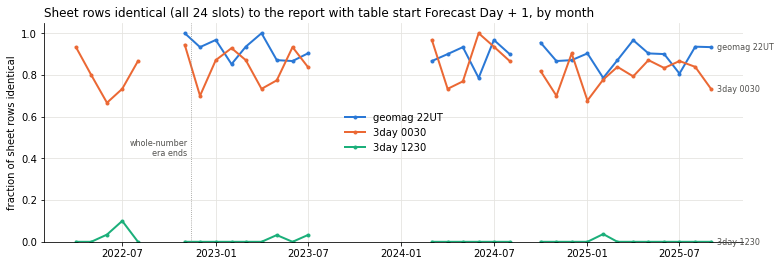

Fraction of rows identical (and number of rows), by era:


geomag 22UT        3day 0030        3day 1230       
                        mean   size      mean   size      mean   size
thirds era             0.904  772.0     0.829  768.0     0.004  770.0
whole-number era       1.000    1.0     0.806  144.0     0.028  142.0

In [15]:
# Fraction of sheet rows identical (all 24 slots, at the product's precision) to each product's report with table start D+1
monthly = {}
ident_all = {}
for name, prod in products.items():
    sh = sheet.copy()
    sh.index = sh.index + pd.Timedelta(days=1)
    idx = sh.index.intersection(prod.index)
    ident = pd.Series(kp_equal(sh.loc[idx].to_numpy(), prod.loc[idx].to_numpy(), idx).all(axis=1), index=idx)
    ident_all[name] = ident
    monthly[name] = ident.groupby(ident.index.to_period('M')).agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(11, 3.8))
for name, mth in monthly.items():
    mth = mth[mth['size'] >= 10]  # skip months with too few reports to give a stable fraction
    s = mth['mean'].reindex(pd.period_range(mth.index.min(), mth.index.max(), freq='M'))  # gaps stay gaps
    ax.plot(s.index.to_timestamp(), s.to_numpy(), color=COLORS[name], lw=2, marker='o', ms=3, label=name)
    last = s.dropna()
    ax.annotate(name, (last.index[-1].to_timestamp(), last.iloc[-1]), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=8, color='#52514e')
ax.axvline(INTEGER_ERA_LAST_START, color=NEUTRAL, lw=0.8, ls=':')
ax.annotate('whole-number\nera ends', (INTEGER_ERA_LAST_START, 0.45), xytext=(-4, 0), textcoords='offset points',
            ha='right', va='center', fontsize=8, color='#52514e')
ax.set_ylim(0, 1.05)
ax.set_ylabel('fraction of sheet rows identical')
ax.set_title('Sheet rows identical (all 24 slots) to the report with table start Forecast Day + 1, by month', loc='left')
ax.legend(frameon=False, loc='center', bbox_to_anchor=(0.5, 0.5))  # sits in the 2023-08 to 2024-02 data gap (no local reports)
fig.tight_layout()
plt.show()

by_era = pd.DataFrame({
    name: ident.groupby(np.where(ident.index <= INTEGER_ERA_LAST_START, 'whole-number era', 'thirds era')).agg(['mean', 'size']).stack()
    for name, ident in ident_all.items()}).unstack()
print('Fraction of rows identical (and number of rows), by era:')
display(by_era.round(3))

**Result.**

- **Whole-number era (2022-03-25 → 2022-11-14).** Compared as is, the sheet never matches a three_day report: 0 % of rows, and only 28 % of slots, which is just the coincidence rate for whole-number values. After rounding to whole numbers, 0030 (*D*+1) matches 97.0 % of slots and 80.6 % of rows, with days 2 and 3 at **100 %** and day 1 at 91 %. That is the same signature as the thirds era. So well before the public products went to thirds, the sheet already held the full-precision values the public products were rounded from. 1230 (*D*+1) again shows the mid-day day-1 update: only 54 % of day-1 slots match even after rounding.
- **Thirds era.** The monthly fraction of identical rows is stable through the whole overlap, with no sign of a change in how the sheet was compiled. geomag runs at 0.79–1.00 per month (90.4 % overall) and 0030 at 0.67–1.00 (82.9 % overall). 1230 stays near zero. 0030 is below geomag in 21 of the 27 months both cover, because of the day-1 revisions in Section 4.
- The gap from mid-August 2023 to February 2024 is missing data. There are no geomag_forecast or three_day_forecast files locally for those dates (see `analysis/*_calander.png`).

## 6. How large are the differences?

This section covers the thirds era only (table start after 2022-11-14), so rounding is not counted as a difference. Each product is compared with the sheet at table start *D*+1. G1 uses the threshold SWPC applies in the three_day tables, Kp ≥ 5− (4.67).

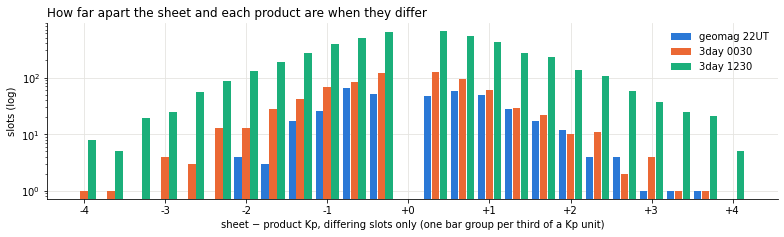

,slots,fraction differing,mean |diff| (all slots),mean |diff| (differing slots),mean diff sheet−product (differing),fraction |diff| ≥ 1,slots with G1+ disagreement
product,,,,,,,
geomag 22UT,18528,0.021,0.019,0.888,0.263,0.009,29
3day 0030,18432,0.040,0.036,0.901,-0.044,0.017,92
3day 1230,18480,0.264,0.284,1.077,0.065,0.137,553


In [16]:
# Size of the differences between the sheet and each product (table start D+1, thirds era only, so rounding
# is not counted as a difference)
def slot_differences(sheet, prod):
    sh = sheet.copy()
    sh.index = sh.index + pd.Timedelta(days=1)
    idx = sh.index.intersection(prod.index[prod.index > INTEGER_ERA_LAST_START])
    return (sh.loc[idx] - prod.loc[idx]).to_numpy().ravel(), sh.loc[idx].to_numpy().ravel(), prod.loc[idx].to_numpy().ravel()


G1 = 4.67  # SWPC flags Kp >= 5- (4.67) as G1 in the three_day_forecast tables
rows = []
fig, ax = plt.subplots(figsize=(11, 3.4))
thirds = np.arange(-12, 13)  # differences in units of one third of a Kp unit
width = 0.28
for j, (name, prod) in enumerate(products.items()):
    d, s, p = slot_differences(sheet, prod)
    nz = d[~np.isclose(d, 0, atol=ATOL)]
    counts = pd.Series(np.round(nz * 3).astype(int)).value_counts().reindex(thirds, fill_value=0)
    rows.append({'product': name, 'slots': d.size, 'fraction differing': nz.size / d.size,
                 'mean |diff| (all slots)': np.abs(d).mean(), 'mean |diff| (differing slots)': np.abs(nz).mean(),
                 'mean diff sheet−product (differing)': nz.mean(),
                 'fraction |diff| ≥ 1': np.mean(np.abs(d) >= 1 - ATOL),
                 'slots with G1+ disagreement': int(((s >= G1 - ATOL) != (p >= G1 - ATOL)).sum())})
    ax.bar(thirds / 3 + (j - 1) * width / 3 * 1.05, counts.replace(0, np.nan), width / 3, color=COLORS[name], label=name)
ax.set_yscale('log')
ax.set_xticks(np.arange(-4, 5), [f'{v:+d}' for v in np.arange(-4, 5)])
ax.set_xlabel('sheet − product Kp, differing slots only (one bar group per third of a Kp unit)')
ax.set_ylabel('slots (log)')
ax.set_title('How far apart the sheet and each product are when they differ', loc='left')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

display(pd.DataFrame(rows).set_index('product').round(3))

**Result** (about 18,500 slots per product):

| product (table start *D*+1) | slots differing | mean \|diff\| when differing | \|diff\| ≥ 1 Kp | slots disagreeing on G1+ |
|---|---|---|---|---|
| geomag 22 UT, *D* | 2.1 % | 0.89 | 0.9 % | 29 |
| three_day 0030, *D*+1 | 4.0 % | 0.90 | 1.7 % | 92 |
| three_day 1230, *D*+1 | 26.4 % | 1.08 | 13.7 % | 553 |

- When the sheet and geomag differ, the gap is typically about one Kp unit, i.e. a real forecaster revision rather than rounding. The sheet is on average higher (mean sheet − geomag = +0.26 on differing slots). So the revisions made after 22 UT that reach the sheet are more often upward than downward.
- Treating geomag_forecast and the sheet as interchangeable changes the G1+ (storm / no storm) call in 29 of ~18,500 slots (0.16 %). For storm-skill analysis, that is small but not zero.
- Using the 1230 report in place of the sheet would change the G1+ call in 553 slots. It is a different, later forecast.

## Conclusions

**Origin.** The SWPC sheet row for Forecast Day *D* is the SWPC forecaster's 3-hourly Kp forecast for *D*+1 … *D*+7, as held at the end of UT day *D*. For the 3-day part:

- **The sheet matches `geomag_forecast` issued at ~22 UT on *D*:** 90.4 % of rows are identical, and 97.9 % of slots.
- **`three_day_forecast` 0030 of *D*+1** is essentially the same forecast, with a late revision to day 1 on about a quarter of days. The sheet picks up some of those revisions (52 days) and keeps the earlier value on more (122). On days 2–3 the sheet agrees with 0030 slightly better than with geomag.
- **`three_day_forecast` 1230** is not the source, from either *D* or *D*+1.
- The sheet stores thirds even in 2022, when the public reports were rounded to whole numbers.

**Implications for this repo.**

1. `Forecast Start = Forecast Day + 1` in `extract_Kp_from_SWPC_sheet` is correct, so no change is needed there.
2. **Issue time (TODO item, resolved):** the sheet values were mostly public by the geomag_forecast issue, 22:00–22:15 UT on *D*, but about 7 % of rows (52 of 767) carry a day-1 revision that was not public until the 0030 three_day_forecast of *D*+1.
   - `extract_Kp_from_SWPC_sheet` now declares the sheet issued at ***D* 21:00 UTC**, just before the geomag_forecast it is anchored to, so `Start Offset (hr)` = 3. The previous *D* 00:00 label overstated the lead time by about a day and compared the sheet against baselines with less observed data than the forecaster had.
   - 21:00 is on the 3 hr grid, so the sheet is compared directly with the baselines issued at *D* 21:00. Both have observed data through the 18–21 UT slot.
   - The day-1 revisions made between the geomag_forecast and the 0030 three_day_forecast (about 7 % of rows) were not public at 21:00, so on those rows the sheet has a slight advantage over the baselines.
3. For dates without a downloaded geomag_forecast (2011 → 2022-11 and the mid-2023-08 → 2024-02 gap), the sheet is a close stand-in for it. It extends the verification record back to 2011, at the cost of ~2 % of slots differing from what was actually published at 22 UT.

**Limitations.**

- Only the first three days of the sheet are checked. No local product covers sheet days 4–7.
- "Equal" means within 0.005 Kp (2 dp rounding).
- The handful of lead days that match neither geomag nor 0030 (9 day-1 and 1 day-2 cases) weren't traced further. They may correspond to amended reports that aren't in the local archive.

## Tests

These are quick checks of the loader and helper functions defined above, following the testing style of `forecast_analysis.ipynb`.

In [17]:
import tempfile
import unittest


class TestForecastOrigin(unittest.TestCase):

    def test_load_three_day_forecast_csv_values(self):
        row = df_3day[df_3day['Slot'] == pd.Timestamp('2024-05-10 00:00')].iloc[0]
        self.assertEqual(row['Product'], '3day 0030')
        self.assertEqual(row['Forecast Issued'], pd.Timestamp('2024-05-10 00:30'))
        self.assertEqual(row['Forecast Start'], pd.Timestamp('2024-05-10'))
        self.assertAlmostEqual(row['3hrKp'], 3.33)    # May 10 00-03UT
        self.assertAlmostEqual(row['24hrKp'], 5.33)   # May 10 21-00UT, '(G1)' tag stripped
        self.assertAlmostEqual(row['33hrKp'], 8.33)   # May 11 06-09UT (G4)
        self.assertAlmostEqual(row['72hrKp'], 3.67)   # May 12 21-00UT

    def test_load_three_day_forecast_csv_slots(self):
        # A late 1230 report (issued 00:20 the next day) stays in its own 1230 slot
        row = df_3day[df_3day['Forecast Issued'] == pd.Timestamp('2024-07-09 00:20')].iloc[0]
        self.assertEqual(row['Slot'], pd.Timestamp('2024-07-08 12:00'))
        self.assertEqual(row['Product'], '3day 1230')
        # Slots are labelled by row position, including the NaN rows for missing reports
        rows = [['2024-01-01 00:30', '2024-01-01', -0.5], ['', '2024-01-01', np.nan], ['2024-01-02 00:30', '2024-01-02', -0.5]]
        df = pd.DataFrame(rows, columns=['Forecast Issued', 'Forecast Start', 'Start Offset (hr)'])
        with tempfile.TemporaryDirectory() as tmp:
            df.to_csv(f'{tmp}/test.csv', index=False)
            out = load_three_day_forecast_csv(f'{tmp}/test.csv')
        self.assertEqual(list(out['Product']), ['3day 0030', '3day 1230', '3day 0030'])
        self.assertEqual(out['Slot'].iloc[1], pd.Timestamp('2024-01-01 12:00'))

    def test_match_on_table_start(self):
        idx = pd.to_datetime(['2024-01-01', '2024-01-02'])
        sh = pd.DataFrame(np.ones((2, 24)), index=idx, columns=LEADS)
        prod = pd.DataFrame(np.ones((2, 24)), index=idx + pd.Timedelta(days=1), columns=LEADS)
        prod.iloc[1, 0] = 2.0
        res = match_on_table_start(sh, prod, lag_days=1)
        self.assertEqual(res['rows'], 2)
        self.assertAlmostEqual(res['slot match'], 47 / 48)
        self.assertAlmostEqual(res['row identical'], 0.5)
        self.assertEqual(match_on_table_start(sh, prod, lag_days=0)['rows'], 1)

    def test_kp_equal_rounds_only_in_whole_number_era(self):
        sheet_vals = np.array([[1.33, 1.67], [1.33, 1.67]])
        prod_vals = np.array([[1.0, 2.0], [1.0, 2.0]])
        starts = pd.to_datetime(['2022-11-14', '2022-11-15'])  # last whole-number day, first thirds day
        np.testing.assert_array_equal(kp_equal(sheet_vals, prod_vals, starts), [[True, True], [False, False]])

    def test_to_valid_time(self):
        idx = pd.to_datetime(['2024-01-01'])
        df = pd.DataFrame([np.arange(24.0)], index=idx, columns=LEADS)
        long = to_valid_time(df, idx.to_series(), idx.to_series() + pd.Timedelta(days=1))
        self.assertEqual(long['valid'].iloc[0], pd.Timestamp('2024-01-02 00:00'))
        self.assertEqual(long['valid'].iloc[-1], pd.Timestamp('2024-01-04 21:00'))
        self.assertEqual(long['Kp'].iloc[9], 9.0)


unittest.main(argv=[''], exit=False, verbosity=2)

test_kp_equal_rounds_only_in_whole_number_era (__main__.TestForecastOrigin.test_kp_equal_rounds_only_in_whole_number_era) ... 

ok


test_load_three_day_forecast_csv_slots (__main__.TestForecastOrigin.test_load_three_day_forecast_csv_slots) ... 

ok


test_load_three_day_forecast_csv_values (__main__.TestForecastOrigin.test_load_three_day_forecast_csv_values) ... 

ok


test_match_on_table_start (__main__.TestForecastOrigin.test_match_on_table_start) ... 

ok


test_to_valid_time (__main__.TestForecastOrigin.test_to_valid_time) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.014s

OK
